# ARTI5001 Assignment 2 - FFHQ128 Variational Autoencoder

**Student name: Jason Liang**  
**Student ID: a1967885**  

Submit this notebook as `<student_id>_<name>_A2.ipynb` after restarting the
kernel and running all cells in order. Keep all required outputs visible.

This notebook provides data-loading infrastructure and evidence headings. It
does not prescribe the assessed model, loss, training loop, or analysis.


## Assessment conditions

- Implement the convolutional VAE, reparameterisation, analytic KL, objective,
  and training/evaluation logic yourself.
- Train the fixed baseline and exactly one approved controlled variant.
- Use the public rubric supplied with the assignment.
- Checkpoint saving is optional and ungraded.
- Complete the mandatory source and AI-use declaration at the end.
- Do not upload FFHQ images or protected course material to external AI tools.


## 1. Reproducible setup and data checks

Configure the experiment in one place. Both runs must use the same seed, split,
batch size, optimiser, learning rate, epoch count, and evaluation procedure.


In [1]:
from pathlib import Path
import copy
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid

DATA_ROOT = Path("./ffhq128")
MANIFEST_PATH = DATA_ROOT / "ffhq128_split_manifest.csv"
IMAGE_ROOT = DATA_ROOT / "images"

SEED = 5001
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
EPOCHS = 15
BASELINE_LATENT_DIM = 16
BASELINE_BETA = 1.0
NUM_WORKERS = 0 # Was 2, I am on Mac so cannot use workers as there is no GPU
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu") # Changed to support MPS as I am on mac
print("Device:", DEVICE)

# Added required constants
VARIANT_BETA = 0.25
OPTIMISER = "AdamW"
WEIGHT_DECAY = 0.0
GRADIENT_CLIP = 5.0

Device: mps


In [2]:
# Supplied infrastructure: do not modify this cell.
class ManifestFFHQ128(Dataset):
    def __init__(self, image_root, manifest_path, split):
        table = pd.read_csv(manifest_path)
        required = {"image_id", "filename", "split"}
        if not required.issubset(table.columns):
            raise ValueError(f"Manifest must contain {sorted(required)}")
        self.rows = table.loc[table["split"] == split].reset_index(drop=True)
        self.image_root = Path(image_root)
        self.to_tensor = ToTensor()

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        path = self.image_root / row["filename"]
        with Image.open(path) as image:
            tensor = self.to_tensor(image.convert("RGB"))
        return tensor, int(row["image_id"])


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def make_loaders():
    datasets = {
        split: ManifestFFHQ128(IMAGE_ROOT, MANIFEST_PATH, split)
        for split in ("train", "val", "test")
    }
    generator = torch.Generator().manual_seed(SEED)
    loaders = {
        "train": DataLoader(datasets["train"], batch_size=BATCH_SIZE,
                            shuffle=True, generator=generator,
                            num_workers=NUM_WORKERS, pin_memory=True),
        "val": DataLoader(datasets["val"], batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=NUM_WORKERS,
                          pin_memory=True),
        "test": DataLoader(datasets["test"], batch_size=BATCH_SIZE,
                           shuffle=False, num_workers=NUM_WORKERS,
                           pin_memory=True),
    }
    return datasets, loaders


set_seed(SEED)
datasets, loaders = make_loaders()


### DISCLAIMER!!!
I am on Mac and hence will get a pin memory error as it is not supported on Mac, there is nothing wrong with my code.
```
/Users/jasonliang/Dev/AIML/VAE-from-Scratch/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
```
This will be error below whenever using DataLoader

Hyperparameters:
Random Seed: 5001
Batch Size: 64
Learning Rate: 0.001
Epochs: 15
Baseline Latent Dimension: 16
Baseline Beta: 1.0
Number of Workers: 0
Variant Beta: 0.25
Optimiser: AdamW
Weight Decay for Optimiser: 0.0
Gradient Clipping Threshold: 5.0

Split: train set, Dataset Size = 30000 images
Split: val set, Dataset Size = 5000 images
Split: test set, Dataset Size = 5000 images

Train, validation and test sets are disjoint

train min pixel value = 0.0000
train max pixel value = 1.0000
train batch shape = torch.Size([64, 3, 128, 128]) | train id shape = torch.Size([64])

val min pixel value = 0.0000
val max pixel value = 1.0000
val batch shape = torch.Size([64, 3, 128, 128]) | val id shape = torch.Size([64])



/Users/jasonliang/Dev/AIML/VAE-from-Scratch/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


test min pixel value = 0.0000
test max pixel value = 1.0000
test batch shape = torch.Size([64, 3, 128, 128]) | test id shape = torch.Size([64])



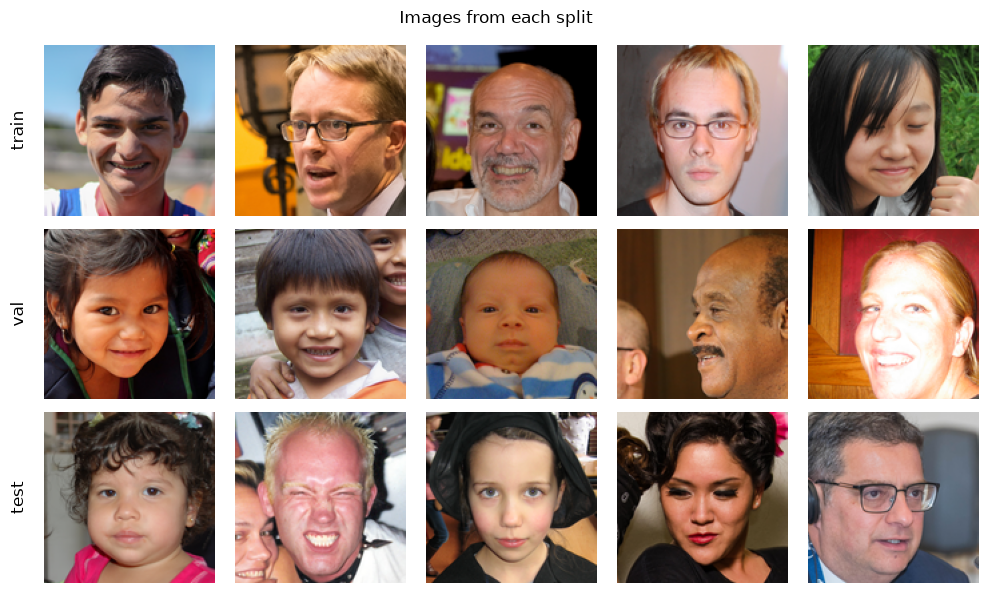

In [3]:
# Show split sizes, batch shape/range, sample images, and any other checks needed to make the pipeline and experiment auditable.

# Confirm hyperparameters
print("Hyperparameters:\n"
    f"Random Seed: {SEED}\n"
    f"Batch Size: {BATCH_SIZE}\n"
    f"Learning Rate: {LEARNING_RATE}\n"
    f"Epochs: {EPOCHS}\n"
    f"Baseline Latent Dimension: {BASELINE_LATENT_DIM}\n"
    f"Baseline Beta: {BASELINE_BETA}\n"
    f"Number of Workers: {NUM_WORKERS}\n"
    f"Variant Beta: {VARIANT_BETA}\n"
    f"Optimiser: {OPTIMISER}\n"
    f"Weight Decay for Optimiser: {WEIGHT_DECAY}\n"
    f"Gradient Clipping Threshold: {GRADIENT_CLIP}\n")

# Confirm split sizes
for split, dataset in datasets.items(): 
    if split == "train": assert len(dataset) == 30000, f"Incorrect train split size {dataset} != 30000"
    elif split == "val": assert len(dataset) == 5000, f"Incorrect val split size {dataset} != 5000"
    elif split == "test": assert len(dataset) == 5000, f"Incorrect test split size {dataset} != 5000"
    print(f"Split: {split} set, Dataset Size = {len(dataset)} images")
print("")

# Confirm no train/val/test set overlap 
table = pd.read_csv(MANIFEST_PATH)
ids = {s: set(table.loc[table["split"] == s, "image_id"]) for s in ("train", "val", "test")}

assert not (ids["train"] & ids["val"]),  "train/val overlap"
assert not (ids["train"] & ids["test"]), "train/test overlap"
assert not (ids["val"] & ids["test"]),   "val/test overlap"
assert table["image_id"].is_unique, "Error, duplicate image_ids in manifest"
print("Train, validation and test sets are disjoint")

print("")

# Confirm tensor sizses
for split, _ in datasets.items():
    batch, ids = next(iter(loaders[split]))
    assert batch.shape == (BATCH_SIZE, 3, 128, 128), f"Incorrect shape: {batch.shape}"
    assert 0.0 <= batch.min() and batch.max() <= 1.0, "Pixel values out of [0, 1] range" # Could use .item() to unwrap the 0D tensor but is uneeded is the problem it solves is serialisation into other libraries 
    assert len(torch.unique(ids)) == len(ids), "Duplicate image IDs found"
    
    print(f"{split} min pixel value = {batch.min():.4f}")
    print(f"{split} max pixel value = {batch.max():.4f}")
    print(f"{split} batch shape = {batch.shape} | {split} id shape = {ids.shape}\n")

# Show sample images
fig, axes = plt.subplots(3, 5, figsize=(10, 6))
fig.suptitle("Images from each split", fontsize=12)

for row, (split, _) in zip(range(3), datasets.items()):
    batch, ids = next(iter(loaders[split]))
    for col in range(5):
        ax = axes[row, col]
        ax.imshow(batch[col].permute(1, 2, 0).numpy()) # (3, 128, 128) to (128, 128, 3) for matplotlib
        ax.axis("off")
    axes[row, 0].text(-0.1, 0.5, split, transform=axes[row, 0].transAxes, fontsize=12, ha="right", va="center", rotation=90)

plt.tight_layout()
plt.show()

## 2. Convolutional VAE architecture

Implement a convolutional encoder and decoder for `3 x 128 x 128` images. The
forward pass must return the reconstruction or logits, `mu`, and `logvar`.
Record the trainable-parameter count and keep it at or below 10 million.

Explain tensor shapes and key architecture decisions in markdown near the code.


#### Tensor Shapes
- Input is batch of 64 x (3, 128, 128) images of 128 x 128 pixels and 3 colours channels, resulting in a (64, 3, 128, 128) tensor in accordance with the thumbnails in FFHQ182.
- It is put into the encoder with 4 conv layers and becomes a 64 series of 256 8 x 8 feature maps, (64, 256, 8, 8). images go from (B, 3, 128, 128) to (B, 32, 64, 64) to (B, 64, 32, 32) to (B, 128, 16, 16) to (B, 256, 8, 8)
- The tensor is then flattened into a tensor of (batch_size, 16,384), where batch_size=64.
- The flattened tensor is then put into the mean and the log variance heads, and is projected into the latent dimension chosen, the baseline case being 16 (batch_size, 16,384) -> (batch_size, 16).
- The two tensors are put through the reparamtisation trick and is output as a single tensor of size (batch_size, 16) called the latent embeddings.
- The reparameterised tensor then enters the decoder where it is projected backout into (batch_size, 16,384).
- The tensor is then unflattened back into shape on exit of the encoder (64, 256, 8, 8).
- The latent feature maps are then put through transposed convolution layers which up samples the maps back into a batch of images, it also has 4 layers transforming the features like so: (B, 256,  8, 8) to (B, 128, 16, 16) to (B, 64, 32, 32) to(B, 32, 64, 64) to (B, 3, 128, 128).
- This is essentially 64 3 x 128 x 128 images being downsampled, reparameterised an upsampled back into 64 3 x 128 x 128 images of faces

#### Encoder 
- The encoder contains the convolution blocks as well as the mean and log variance heads.
- The there are 4 blocks with each have 3 layers:
  - Each layer downsamples the images/features maps to obtain a better generalisation of the images.
  - The tensor then gets normalised to help reduce the chance of exploding and vanishing gradients.
  - The tensor is then put through ReLU to introduce non-linearity and sparsity.
- The encoder then contains two separate linear layers which do not flow into each other, the latent representations from the encoder flow into both heads that being the mean and log variance heads both with 16 nodes.
- We clamp the log variance to [-10, 10] to prevent numerical instability and exploding gradients during the computation of KL Divergence and the reparameterisation trick.

#### Decoder 
- The decoder receives the tensor of (batch_size, 16), which is the latent representations after being put through the reparameterisation trick.
- It then enters a linear layer with 16384 upscaling the tensor.
- It then unflattens the tensor back into the shape (64, 256, 8, 8).
- After this it enters the 4 transposed convolution blocks.
  - Each block starts with a transpose convolution layer upsampling the representations.
  - The tensor then gets normalised to help reduce the chance of exploding and vanishing gradients.
  - On the first 3 blocks the tensor is then put through ReLU to introduce non-linearity and sparsity.
  - On the final block the sigmoid activation function is used to squash the values into the range of [0.0, 1.0] for loss processing and image normalising

#### VAE
- The VAE contains an Encoder and a Decoder as well as the logic reparameterisation trick.
- It controls the flow of batches Encoder -> Reparameterisation -> Decoder
- During training (`model.train()`), the reparameterisation function samples $z = \mu + \sigma \odot \epsilon$ with $\sigma = \exp(0.5 \cdot \text{log\_var})$ and $\epsilon \sim \mathcal{N}(0, I)$ so gradients can backpropagate through the sampling process while regularising the posterior distribution. During validation and testing (`model.eval()`), the reparameterisation function returns the deterministic posterior mean ($z = \mu$, the maximum a posteriori point estimate). This removes the single sample variance during evaluation like in inference to ensure deterministic, repeatable validation/test metrics.

In [4]:
# Implement your convolutional VAE here.
class Encoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1), # images go from (B, 3, 128, 128) to (B, 32, 64, 64)
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), # images go from (B, 32, 64, 64) to (B, 64, 32, 32)
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # images go from (B, 64, 32, 32) to (B, 128, 16, 16)
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1), # images go from (B, 128, 16, 16) to (B, 256, 8, 8)
            nn.BatchNorm2d(256),
            nn.ReLU(),
        )
        self.flat_dim = 16384 # 256 * 8 * 8

        self.mu_layer = nn.Linear(self.flat_dim, latent_dim)
        self.log_var_layer = nn.Linear(self.flat_dim, latent_dim)

    def forward(self, x):
        h = self.conv(x) # x is raw input h indicates features/hiddens states
        h = h.view(h.size(0), -1)

        mu = self.mu_layer(h)
        log_var = self.log_var_layer(h)
        log_var = torch.clamp(log_var, min=-10.0, max=10.0)
        
        return mu, log_var

class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.flat_dim = 16384

        self.project = nn.Sequential(
            # Project from latent dimension into the flattened dimension
            nn.Linear(latent_dim, self.flat_dim),
            nn.ReLU(),

            nn.Unflatten(1, (256, 8, 8)), # Unflatten dim 1 into (channels, height, width)
            
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1), # (B, 256, 8, 8) to (B, 128, 16, 16)
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1), # (B, 128, 16, 16) to (B, 64, 32, 32)
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1), # (B, 64, 32, 32) to (B, 32, 64, 64)
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1), # (B, 32, 64, 64) to (B, 3, 128, 128)
            nn.Sigmoid(),
        )
        
    def forward(self, z):  return self.project(z)
            

class VAE(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)
        self.latent_dim = latent_dim

    def reparameterise(self, mu, log_var):
        if self.training:
            std = torch.exp(log_var * 0.5)
            epsilon = torch.randn_like(std)
            return mu + std * epsilon
        return mu 

    def forward(self, x):
        mu, log_var = self.encoder(x)
        z = self.reparameterise(mu, log_var)
        x_hat = self.decoder(z)
        return x_hat, mu, log_var

In [5]:
# Instantiate a baseline model and display shape and parameter-count checks.
set_seed(SEED)
model = VAE(latent_dim=BASELINE_LATENT_DIM).to(DEVICE)

total_params = sum(param.numel() for param in model.parameters() if param.requires_grad)
assert total_params <= 10_000_000, f"Error {total_params} exceeds 10,000,000 max parameters"
print(f"Model Parameters: {total_params}")

test = torch.zeros(BATCH_SIZE, 3, 128, 128).to(DEVICE)
out, mu, log_var = model(test)
print(f"Test Tensor: {tuple(test.shape)}")
assert out.shape == (BATCH_SIZE, 3, 128, 128), f"Error {tuple(out.shape)} does not equal ({BATCH_SIZE}, 3, 128, 128)"
print(f"Output Tensor: {tuple(out.shape)}")
print(f"Mean Tensor: {tuple(mu.shape)}") 
print(f"Log Variance Tensor: {tuple(log_var.shape)}")


Model Parameters: 2184291
Test Tensor: (64, 3, 128, 128)
Output Tensor: (64, 3, 128, 128)
Mean Tensor: (64, 16)
Log Variance Tensor: (64, 16)


## 3. VAE objective and verification

Implement a reconstruction term, analytic diagonal-Gaussian KL against `N(0,I)`, and `reconstruction + beta * KL`. Use and document a coherent per-image reduction. Report unweighted KL separately.


The reconstruction loss (rl) and KL divergence (kld) are both reduced to mean loss per image as each is summed over its own internal dimensions then averaged across the batch. This allows both terms to be on a 'per-image-scale' so beta's weighted is consistently against rl and kld regardless of batch size.

In [6]:
# Implement the reconstruction term, KL term, and total objective here.

# Returns the binary cross entropy
def reconstruction_loss(x, x_hat): return F.binary_cross_entropy(x_hat, x, reduction='sum') / x.size(0) 

# Takes the batch of tensors and caluculates the mean KL Divergence over each tensor  
def kl_divergence(mu, log_var): 
    kld = (-0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp(), dim=1))
    return kld.mean() 

def elbo(x, x_hat, mu, log_var, beta):
    r_loss = reconstruction_loss(x, x_hat)
    kld = kl_divergence(mu, log_var)
    loss = r_loss + beta * kld 
    return loss, r_loss, kld


In [7]:
# Run shape, finite-loss, and KL non-negativity checks here.

loss, rl, kld = elbo(test, out, mu, log_var, BASELINE_BETA)

assert loss.dim() == 0 and rl.dim() == 0 and kld.dim() == 0, "losses should be scalars"
assert torch.isfinite(rl), "Reconstruction loss is not finite"
assert torch.isfinite(kld),"KL Divergence loss is not finite"
assert torch.isfinite(loss), "Total Loss is not finite"

assert kld.item() >= -1e-6, f"KL is negative: {kld.item()}" # Done as -1e-6 as PyTorch can have very small floating point errors
assert torch.isclose(loss, rl + BASELINE_BETA * kld), "total != recon + beta*KL"
assert torch.isclose(elbo(test, out, mu, log_var, 0.0)[0], rl), "beta=0 should give recon only"

print("Losses are scalar")
print("KL Divergence is positive")
print("Total Loss = Reconstruction Loss + Beta * KL Divergence")
print("Given that Beta is 0 the total loss is only the reconstruction loss\n")

print(f"Sample Reconstruction Loss : {rl.item():.4f}")
print(f"Sample KL Divergence Loss : {kld.item():.4f}")
print(f"Sample Loss: {loss:.4f}")

Losses are scalar
KL Divergence is positive
Total Loss = Reconstruction Loss + Beta * KL Divergence
Given that Beta is 0 the total loss is only the reconstruction loss

Sample Reconstruction Loss : 37837.8711
Sample KL Divergence Loss : 0.6658
Sample Loss: 37838.5352


## 4. Training and validation

For every epoch, retain train and validation total, reconstruction, and
unweighted KL values. Both baseline and variant must run for 15 epochs under
the same declared controls.


In [8]:
# Implement reusable training and evaluation functions here.
# The implementation must make the history for all six required series easy to audit.

def train_one_epoch(model, loader, optimiser, beta, device): 
    model.train() # Confirm training mode 
    avg_reconstruction_loss = 0.0
    avg_kl_loss = 0.0
    avg_loss = 0.0
    num_images = 0
    for images, _ in loader:
        images = images.to(device)
        batch_size = images.size(0)

        optimiser.zero_grad()
        x_hat, mu, log_var = model(images)
        loss, rl, kld = elbo(images, x_hat, mu, log_var, beta)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRADIENT_CLIP) # Used to stablise training
        optimiser.step() # Updates model weights aand biases 
        
        avg_reconstruction_loss += rl.item() * batch_size
        avg_kl_loss += kld.item() * batch_size
        avg_loss += loss.item() * batch_size
        num_images += batch_size
    n = len(loader)
    return avg_loss/num_images, avg_reconstruction_loss/num_images, avg_kl_loss/num_images

@torch.no_grad() # No backpropogation and hence no gradients required
def validate_one_epoch(model, loader, beta, device): 
    model.eval() # Deactivates BatchNorm
    avg_reconstruction_loss = 0.0
    avg_kl_loss = 0.0
    avg_loss = 0.0
    num_images = 0

    for images, _ in loader:
        images = images.to(device)
        batch_size = images.size(0)

        x_hat, mu, log_var = model(images)
        loss, rl, kld = elbo(images, x_hat, mu, log_var, beta)
        
        avg_reconstruction_loss += rl.item() * batch_size
        avg_kl_loss += kld.item() * batch_size
        avg_loss += loss.item() * batch_size
        num_images += batch_size
            
    return avg_loss/num_images, avg_reconstruction_loss/num_images, avg_kl_loss/num_images
    

def fit(model, loader, optimiser, epochs, beta, device):
    history = {"train_loss" : [], "train_rl" : [], "train_kld" : [], "val_loss" : [], "val_rl" : [], "val_kld" : []}
    for epoch in range(1, epochs + 1):
        t_loss, t_rl, t_kld = train_one_epoch(model, loader["train"], optimiser, beta, device)
        v_loss, v_rl, v_kld = validate_one_epoch(model, loader["val"], beta, device)
        
        history["train_loss"].append(t_loss)
        history["train_rl"].append(t_rl)
        history["train_kld"].append(t_kld)
        history["val_loss"].append(v_loss)
        history["val_rl"].append(v_rl)
        history["val_kld"].append(v_kld)

        print(
            f"Epoch {epoch:02d}/{epochs}\n"
            f"Train — Total Loss: {t_loss:.4f}, Reconstruction Loss: {t_rl:.4f}, KL Divergence: {t_kld:.4f}\n"
            f"Val   — Total Loss: {v_loss:.4f}, Reconstruction Loss: {v_rl:.4f}, KL Divergence: {v_kld:.4f}"
        )
    
    return history

### 4.1 Baseline run

Baseline condition: `latent_dim=16`, fixed `beta=1.0`, 15 epochs, no data
augmentation. State optimiser and learning-rate rationale before training.


#### Training Methods Rationale

The optimiser used for training is AdamW as compared with normal Adam it has true weight decay instead of L2 regularisation. It reduces the weights by subtracting a small fraction of their current value during each step however in our use case we set it to 0.0, this is as we are experimenting with Beta and comparing two models performance. By setting the true weight decay to 0.0 we no longer have a regularisation term ontop of the KL Divergence during training. As Beta controls the magnitude of the KL Divergence and Beta is the only changing hyperparameter in the variant model below we want to ensure that KL Divergence is the only regularisation used so that any difference observed is attributed to the beta rather than another regularisation term.

The fixed learning rate chosen for the experiment is the default 0.001/1e-3  as it is the PyTorch default for AdamW. 0.001 is the standard starting point for computer vision networks as it is a heuristic sweet spot for not overshooting maxima whilst also being quick to converge. AdamW normalises each update by gradient magnitude, so the large scale of the reconstruction loss does not require adjusting the LR and BatchNorm tolerates a rate of this size smoothing the terrain for the optimiser.

In [9]:
# Reset the seed, recreate the loaders, then instantiate, train, and
# validate the baseline here. Recreating loaders resets the shuffle generator.
print("=== BASELINE MODEL TRAINING ===")

set_seed(SEED)
_, baseline_loaders = make_loaders()
baseline_model = VAE(latent_dim=BASELINE_LATENT_DIM).to(DEVICE)
baseline_optimiser = torch.optim.AdamW(baseline_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
baseline_train_val_history = fit(baseline_model, baseline_loaders, baseline_optimiser, EPOCHS, BASELINE_BETA, DEVICE)

=== BASELINE MODEL TRAINING ===


/Users/jasonliang/Dev/AIML/VAE-from-Scratch/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch 01/15
Train — Total Loss: 29022.0392, Reconstruction Loss: 28904.9097, KL Divergence: 117.1294
Val   — Total Loss: 28514.6755, Reconstruction Loss: 28433.7140, KL Divergence: 80.9616
Epoch 02/15
Train — Total Loss: 28360.2523, Reconstruction Loss: 28299.2360, KL Divergence: 61.0163
Val   — Total Loss: 28322.0410, Reconstruction Loss: 28261.2315, KL Divergence: 60.8096
Epoch 03/15
Train — Total Loss: 28229.6655, Reconstruction Loss: 28174.4731, KL Divergence: 55.1924
Val   — Total Loss: 28244.1905, Reconstruction Loss: 28189.5183, KL Divergence: 54.6722
Epoch 04/15
Train — Total Loss: 28174.3434, Reconstruction Loss: 28120.3974, KL Divergence: 53.9460
Val   — Total Loss: 28207.7537, Reconstruction Loss: 28152.8172, KL Divergence: 54.9365
Epoch 05/15
Train — Total Loss: 28146.6908, Reconstruction Loss: 28092.6246, KL Divergence: 54.0662
Val   — Total Loss: 28200.7332, Reconstruction Loss: 28148.4457, KL Divergence: 52.2874
Epoch 06/15
Train — Total Loss: 28117.4644, Reconstruction 

### 4.2 Controlled variant

Select exactly one:

- latent dimension 16 to 32;
- fixed beta 1.0 to 0.25 or 2.0;
- fixed beta 1.0 to linear warm-up from 0 to 1 over the first 30% of epochs.

**Selected factor: beta = 0.25**  
**Prediction before examining**  
- Reducing beta will decreases the KL Divergence penalty as beta scaled the Kl Divergence losss = reconstruction + beta * KL.
- This means that the KL Divergence will act as a weaker reguliser on the reconstruction loss.
- As a result the cheaper penalty will model lets its reconstruction stray more from the standard shape (N(0,1)).
- However, KL Divergence measures the difference in distribution, the more difference the higher the KL Divergence.
- The raw KL will end up being greater in the variant than the model.
- Due to the high scale of the reconstruction loss it could be slightly lower than the baseline due to the KLD.
- The rubberbanding of the slightly lower reconstruction and the scaled down greater raw KLD the total loss will remain largely unchanged.
- As for the actual reconstructions visually 15 epochs is too little to see a difference in generations even with different Beta. 

**Controls held constant:**
- Data Split
- Random Seed
- Architecture
- latent_dim = 16
- Batch Size = 64
- Optimiser = AdamW
- Learning rate = 1e-3
- Weight Decay = 0.0
- Number of Epochs = 15

In [10]:
# Reset the same seed, recreate the loaders, then instantiate, train, and
# validate the variant here. Recreating loaders resets the shuffle generator.
print("=== VARIANT MODEL TRAINING ===")

set_seed(SEED)
_, variant_loaders = make_loaders()
variant_model = VAE(latent_dim=BASELINE_LATENT_DIM).to(DEVICE)
variant_optimiser = torch.optim.AdamW(variant_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
variant_train_val_history = fit(variant_model, variant_loaders, variant_optimiser, EPOCHS, VARIANT_BETA, DEVICE)


=== VARIANT MODEL TRAINING ===


/Users/jasonliang/Dev/AIML/VAE-from-Scratch/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch 01/15
Train — Total Loss: 28915.0171, Reconstruction Loss: 28847.9950, KL Divergence: 268.0886
Val   — Total Loss: 28378.2037, Reconstruction Loss: 28336.9234, KL Divergence: 165.1208
Epoch 02/15
Train — Total Loss: 28283.5050, Reconstruction Loss: 28252.2953, KL Divergence: 124.8389
Val   — Total Loss: 28300.9651, Reconstruction Loss: 28276.0895, KL Divergence: 99.5028
Epoch 03/15
Train — Total Loss: 28179.7761, Reconstruction Loss: 28158.0885, KL Divergence: 86.7502
Val   — Total Loss: 28217.6265, Reconstruction Loss: 28197.1518, KL Divergence: 81.8988
Epoch 04/15
Train — Total Loss: 28134.3494, Reconstruction Loss: 28114.9378, KL Divergence: 77.6461
Val   — Total Loss: 28147.6721, Reconstruction Loss: 28129.1441, KL Divergence: 74.1116
Epoch 05/15
Train — Total Loss: 28109.2254, Reconstruction Loss: 28090.4733, KL Divergence: 75.0086
Val   — Total Loss: 28145.8905, Reconstruction Loss: 28127.4117, KL Divergence: 73.9149
Epoch 06/15
Train — Total Loss: 28082.6271, Reconstructio

## 5. Required evaluation evidence

Use the same test examples, interpolation endpoints, and generation seed for
both models. Clearly identify baseline and variant in every table and figure.


### 5.1 Quantitative test comparison

Report mean per-image reconstruction, unweighted KL, and total objective for
both models.


In [11]:
# Create and display the baseline-versus-variant test result table here.
@torch.no_grad()
def test(model, loader, beta, device): # Copy of validate_one_epoch they functionally do the same thing
    model.eval()
    avg_reconstruction_loss = 0.0
    avg_kl_loss = 0.0
    avg_loss = 0.0
    num_images = 0

    for images, _ in loader:
        images = images.to(device)
        batch_size = images.size(0)

        x_hat, mu, log_var = model(images)
        loss, rl, kld = elbo(images, x_hat, mu, log_var, beta)
        
        avg_reconstruction_loss += rl.item() * batch_size
        avg_kl_loss += kld.item() * batch_size
        avg_loss += loss.item() * batch_size
        num_images += batch_size
            
    return avg_loss/num_images, avg_reconstruction_loss/num_images, avg_kl_loss/num_images

set_seed(SEED)
baseline_test_loss, baseline_test_rl, baseline_test_kld = test(baseline_model, baseline_loaders["test"], BASELINE_BETA, DEVICE)
variant_test_loss, variant_test_rl, variant_test_kld = test(variant_model, variant_loaders["test"], VARIANT_BETA, DEVICE)

test_results = pd.DataFrame([
    {
        "Model": f"Baseline (beta={BASELINE_BETA})",
        "Test Reconstruction Loss (nats/img)": round(baseline_test_rl, 4),
        "Test Unweighted KL Divergence (nats/img)": round(baseline_test_kld, 4),
        "Test Total Objective (nats/img)": round(baseline_test_loss, 4),
    },
    {
        "Model": f"Variant (beta={VARIANT_BETA})",
        "Test Reconstruction Loss (nats/img)": round(variant_test_rl, 4),
        "Test Unweighted KL Divergence (nats/img)": round(variant_test_kld, 4),
        "Test Total Objective (nats/img)": round(variant_test_loss, 4),
    },
])
display(test_results)

,Model,Test Reconstruction Loss (nats/img),Test Unweighted KL Divergence (nats/img),Test Total Objective (nats/img)
0,Baseline (beta=1.0),28021.3544,53.4943,28074.8486
1,Variant (beta=0.25),28022.6779,69.1273,28039.9598


### 5.2 Reconstruction comparison

Show the same 12 test images as original, baseline reconstruction, and variant reconstruction.

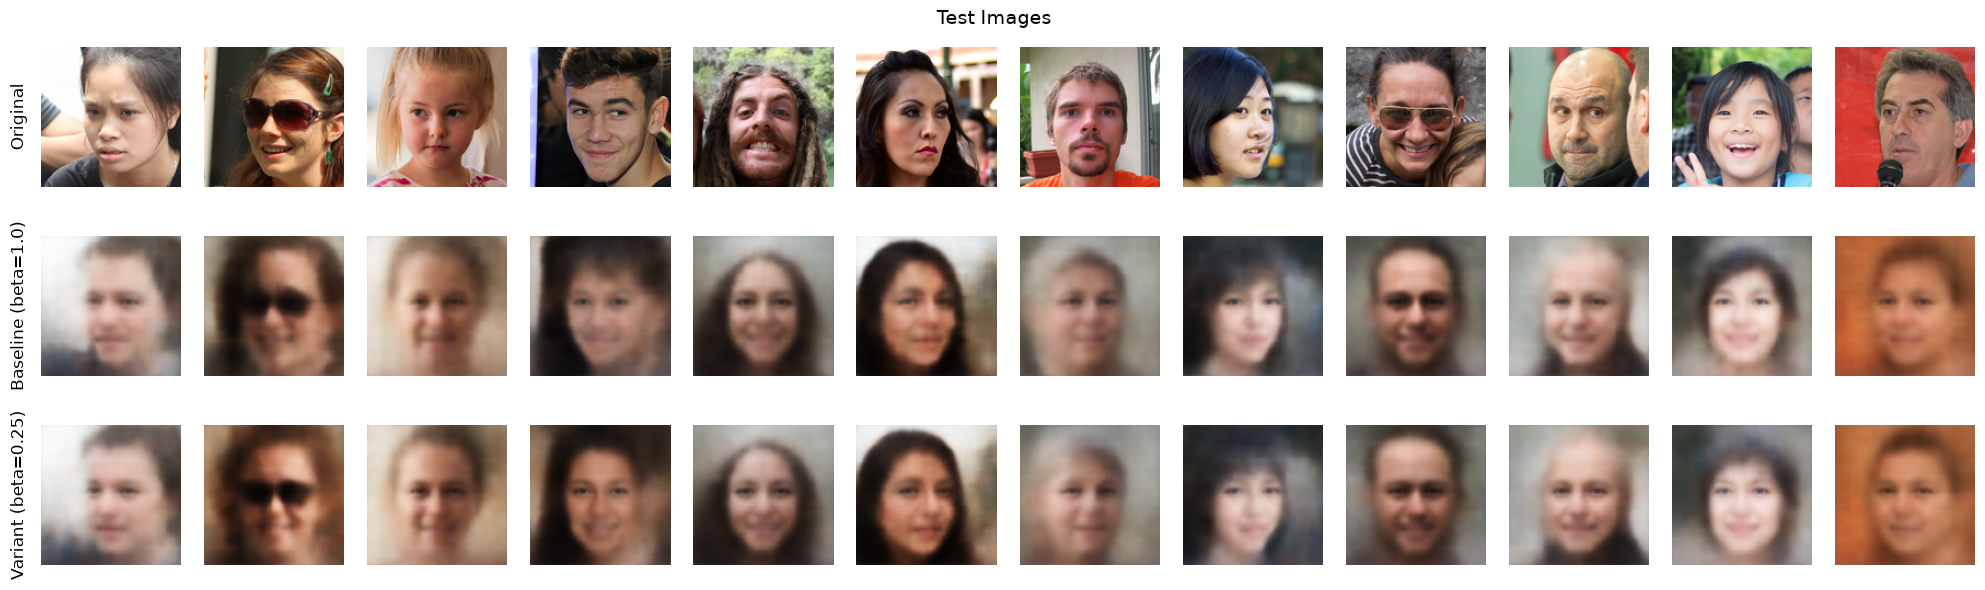

In [12]:
# Produce the required reconstruction comparison here.

NUM_EVAL_IMAGES = 12

gen = torch.Generator().manual_seed(SEED) # Create random permutation of the test set
eval_image_ids = torch.randperm(len(datasets["test"]), generator=gen)[0:NUM_EVAL_IMAGES].tolist()
eval_images = torch.stack([datasets["test"][i][0] for i in eval_image_ids]).to(DEVICE)

@torch.no_grad()
def inference(model, images):
    model.eval()
    x_hat, _, _ = model(images)
    return x_hat

original_images = eval_images
baseline_output = inference(baseline_model, eval_images)
variant_output = inference(variant_model, eval_images)

fig, axes = plt.subplots(3, NUM_EVAL_IMAGES, figsize=(20, 6))
fig.suptitle("Test Images", fontsize=14)

row_labels = ["Original", f"Baseline (beta={BASELINE_BETA})", f"Variant (beta={VARIANT_BETA})"]
row_tensors = [original_images, baseline_output, variant_output]

for row in range(3):
    for col in range(NUM_EVAL_IMAGES):
        ax = axes[row, col]
        ax.imshow(row_tensors[row][col].permute(1, 2, 0).clamp(0, 1).cpu().numpy()) # Use clamp here to ensure values are bettwen 0 and 1
        ax.axis("off")
    axes[row, 0].text(-0.1, 0.5, row_labels[row], transform=axes[row, 0].transAxes, fontsize=12, ha="right", va="center", rotation=90)
plt.tight_layout()
plt.show()

### 5.3 Prior samples

Show at least 64 samples from each model in an 8 by 8 grid, using the same
generation seed.


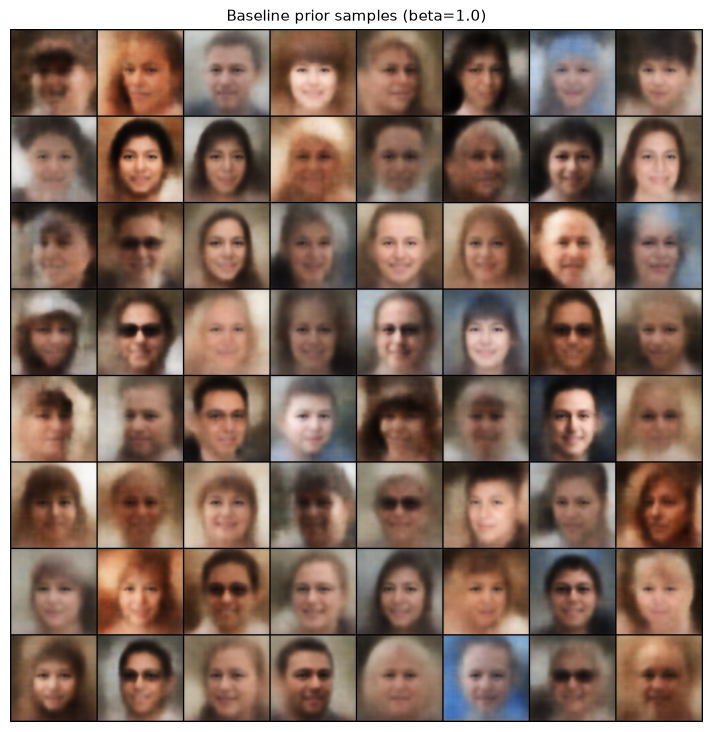

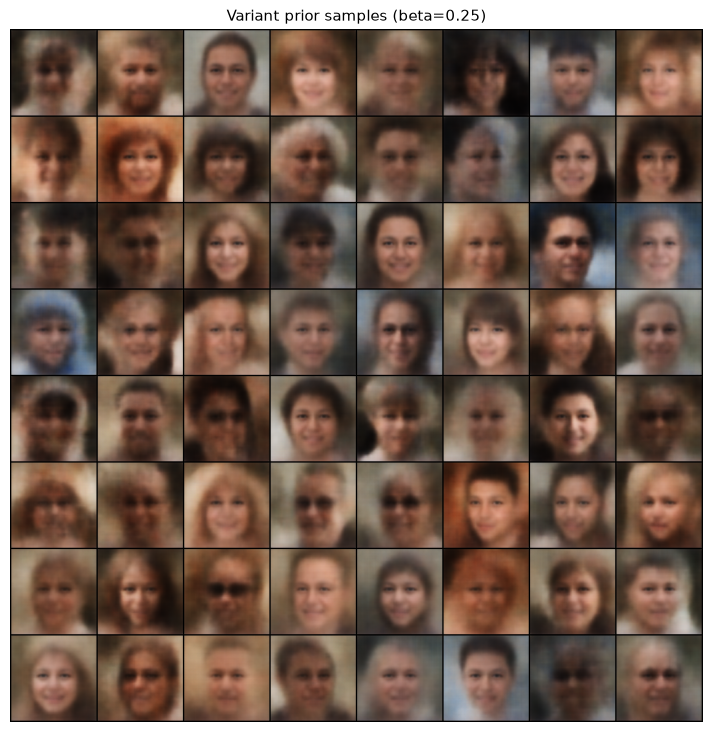

In [13]:
# Produce the baseline and variant prior-sample grids here.

# Prior samples are those with pure random noise input
@torch.no_grad()
def sample_prior(model, n_samples, device, seed):
    model.eval()
    gen = torch.Generator().manual_seed(seed)
    z = torch.randn(n_samples, model.latent_dim, generator=gen).to(device)
    return model.decoder(z).cpu()

baseline_samples = sample_prior(baseline_model, 64, DEVICE, SEED)
variant_samples = sample_prior(variant_model, 64, DEVICE, SEED)

def show_grid(images, title):
    grid = make_grid(images, nrow=8)
    plt.figure(figsize=(9, 9))
    plt.imshow(grid.permute(1, 2, 0).clamp(0, 1).numpy())
    plt.title(title, fontsize=11)
    plt.axis("off")
    plt.show()

show_grid(baseline_samples, f"Baseline prior samples (beta={BASELINE_BETA})")
show_grid(variant_samples, f"Variant prior samples (beta={VARIANT_BETA})")


### 5.4 Latent interpolation

Use at least 12 interpolation steps between the same two encoded test images
for both models.


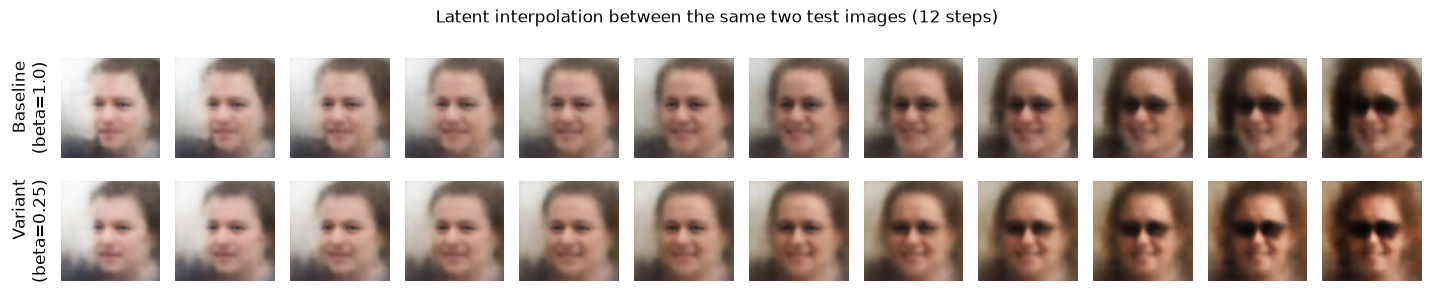

In [14]:
# Produce both latent interpolations here.
STEPS = 12
start, end = eval_images[0:1], eval_images[1:2]

@torch.no_grad()
def interpolate(model, start, end, steps):
    model.eval()
    
    mu_start, _ = model.encoder(start)
    mu_end, _ = model.encoder(end)
    
    alphas = torch.linspace(0, 1, steps, device=start.device).view(-1, 1)
    z_interp = (1 - alphas) * mu_start + alphas * mu_end
    
    return model.decoder(z_interp).cpu()

baseline_interpolation = interpolate(baseline_model, start, end, STEPS)
variant_interpolation = interpolate(variant_model, start, end, STEPS)

fig, axes = plt.subplots(2, STEPS, figsize=(STEPS * 1.2, 3))
fig.suptitle(f"Latent interpolation between the same two test images ({STEPS} steps)", fontsize=12)

for col in range(STEPS):
    axes[0, col].imshow(baseline_interpolation[col].permute(1, 2, 0).clamp(0, 1).numpy())
    axes[0, col].axis("off")
    axes[1, col].imshow(variant_interpolation[col].permute(1, 2, 0).clamp(0, 1).numpy())
    axes[1, col].axis("off")

axes[0, 0].text(-0.1, 0.5, f"Baseline\n(beta={BASELINE_BETA})", transform=axes[0, 0].transAxes, fontsize=12, ha="right", va="center", rotation=90)
axes[1, 0].text(-0.1, 0.5, f"Variant\n(beta={VARIANT_BETA})", transform=axes[1, 0].transAxes, fontsize=12, ha="right", va="center", rotation=90)

plt.tight_layout()
plt.show()


### 5.5 Training and validation curves

Plot total, reconstruction, and unweighted KL for train and validation for both
models. Labels must distinguish model, split, and loss component.


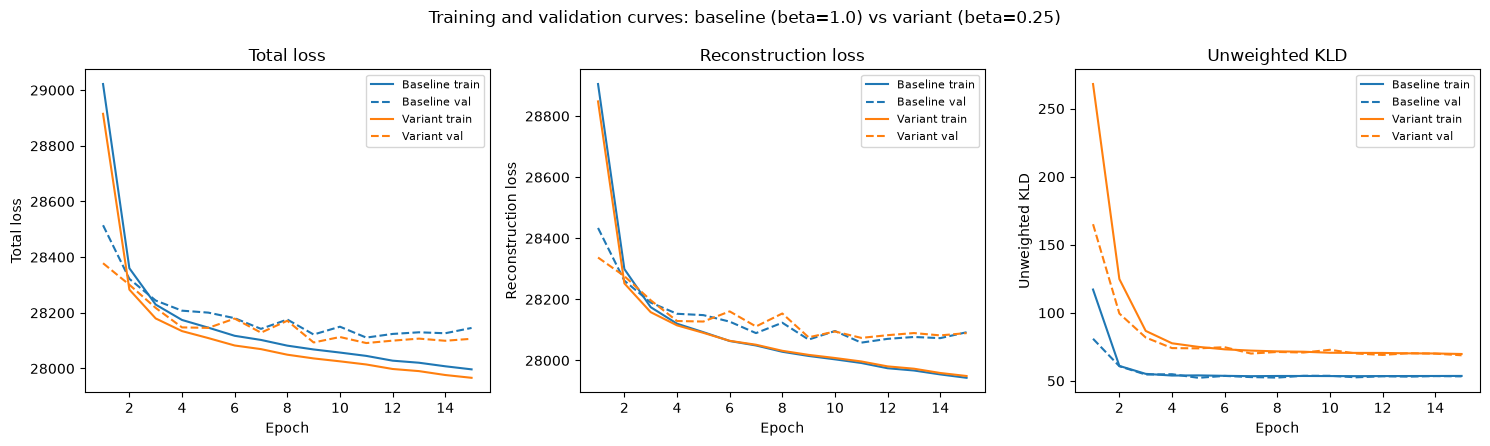

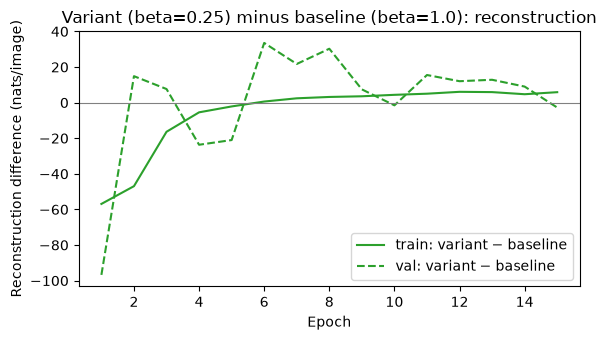

In [15]:
# Produce the required comparison curves here.

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle(f"Training and validation curves: baseline (beta={BASELINE_BETA}) vs variant (beta={VARIANT_BETA})", fontsize=12)
epochs_range = range(1, EPOCHS + 1)
series = [("loss", "Total loss"), ("rl", "Reconstruction loss"), ("kld", "Unweighted KLD")]

for ax, (key, title) in zip(axes, series):
    ax.plot(epochs_range, baseline_train_val_history[f"train_{key}"], color="tab:blue", linestyle="-", label="Baseline train")
    ax.plot(epochs_range, baseline_train_val_history[f"val_{key}"], color="tab:blue", linestyle="--", label="Baseline val")
    ax.plot(epochs_range, variant_train_val_history[f"train_{key}"], color="tab:orange", linestyle="-", label="Variant train")
    ax.plot(epochs_range, variant_train_val_history[f"val_{key}"], color="tab:orange", linestyle="--", label="Variant val")
    
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
ep = range(1, EPOCHS + 1)
for split, style in (("train", "-"), ("val", "--")):
    diff = np.array(variant_train_val_history[f"{split}_rl"]) - np.array(baseline_train_val_history[f"{split}_rl"])
    ax.plot(ep, diff, style, color="tab:green", label=f"{split}: variant − baseline")
    
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Epoch")
ax.set_ylabel("Reconstruction difference (nats/image)")
ax.set_title("Variant (beta=0.25) minus baseline (beta=1.0): reconstruction")
ax.legend()

plt.tight_layout()
plt.show()


## 6. Notebook report

### A. Design rationale

Explain the architecture, reconstruction term, decoder output, optimiser,
learning rate, and stability choices. Tie each choice to FFHQ128 and your model.

**Response:**

The architecture used for this model was a standard VAE. It features an encoder which has four convolutional blocks with a 4×4 kernel, stride 2 convolution downsample layers followed by BatchNorm and ReLU each. The channels grow as increase with each layer: 3→32→64→128→256 whilst downsampling the 128x128 face down to 8x8 features. The 256×8×8 features are then flattened into a batches by 16,384 tensor and then put into two separate linear heads, mu and log_var, each of size 16. Flattening keeps a consistent remappable spatial layout, which is important for FFHQ eyes, nose and mouth sit in consistent positions on human faces. 

The VAE itself holds the reparameterisation trick ($z = \mu + \exp(0.5 \cdot \text{log\_var}) \odot \epsilon$) which then transforms the vectors values. It was coded so that during training backpropagation can flow through the deterministic equation so the encoder learns a smooth distribution. Whilst during evaluation (`model.eval()`), the model deterministically passes the posterior mean $z = \mu$ to the decoder for inference and preventing random variance be added to the validation and test runs.

The decoder then projects the reparameterised tensor back into 256×8×8, then four 4×4, stride 2 transposed convolution layers which upsample the batch back into 3×128×128 images. The chosen kernel size is divisible by the stride to reduce checkerboard artefacts. The model has around 2.18M trainable parameters, under the 10M limit imposed by the assignment. The 16 dimension bottleneck is fixed by the assignment and forces the code to capture global attributes such as pose, lighting, and face shape through occlusions, so I expect smooth reconstructions rather than sharp fine detail especially due to the limited number of epochs. These shapes from input to output match the 128x128 thumbnails in FFHQ128.

The reconstruction term uses Binary Cross Entropy summed over all 3x128x128 images, which gives 49,152 values per image which are averaged over the batch. Without it is a mean over pixels which would shrink the reconstruction loss by about 49,000× and let the KL Divergence dominate the loss. Summing over the pixels keeps the reconstruction and KL terms on a per image image scale for ELBO. This allows the VAE to treat every pixel in the image as an independent Bernoulli trial making the output of the decoder network into the probability that each pixel should be bright (1) or dark (0). The reconstruction loss is the main part of the ELBO loss, and it represents how well the decoder is able to generate the original input data from a sample drawn from the latent space. 

The decoder ends in a sigmoid, so that the outputs lie in the range of [0, 1], this matches the [0, 1] pixel range supplied to the model as PyTorch does not take standard 0-256 pixel values. It outputs of the same dimensions as the input in this case being (64, 3, 128, 128).

The optimiser used was AdamW with its weight decay set to 0, this is as we are experimenting with Beta and comparing two models performance. By setting the weight decay to 0.0 we no longer have a regularisation term ontop of the KL Divergence during training which acts as a regularisation term. As beta controls the magnitude of the KL Divergence and effecy of beta is being tested as we want to ensure that KL Divergence is the only regularisation used so that any difference observed is attributed to the beta rather than another regularisation term.

The learning rate used with AdamW is 1e-3, it is the library default and a standard starting point for convolutional networks.  The Adam family optimisers use gradient magnitude for parameter updates, hence the large scale of the summed loss doesn’t require retuning the learning rate, furthermore BatchNorm layers tolerates a learning rate of this size. It is kept fixed with no scheduler because 15 epochs is not a long amount of time and a scheduler would add untuned hyperparameters as well as more changing variables other than the beta that we are testing.

To keep the model training stable the BatchNorm layer in every block stabilises activations. Furthermore, we clamp the output of the log_var to [−10, 10], which keeps exp(log_var) finite and the KL term bounded. In addition, the gradient norms are clipped at 5.0 as a guard against large updates from the high scale loss. For each experiment the seed is reset before each run, so both models start from identical initial weights and have the same shuffle order.


### B. Controlled comparison

Evaluate your prediction using at least three exact own-run values and at least three specific figure observations. Explain the reconstruction-KL trade-off and identify at least one visible failure case.

**Response:**

**Test Observations:**

| Model | Loss | Reconstruction Loss | KL Divergence | 
|---|---|---|---|
| Baseline ($\beta = 1.0$)| 28074.8486 | 28021.3544 | 53.4943 |
| Variant ($\beta = 0.25$)| 28039.9598 | 28022.6779 | 69.1273 |
| Variant - Baseline | -34.8888 | 1.3235 | 15.6330 |

My initial prediction was that reducing beta will decreases the magnitude of the KL Divergence penalty, however the KL Divergence measures the difference in distribution, as the penalty is weaker there will be more difference which results in a higher KL Divergence. Due to this the KL divergence will end up being greater in the variant than the baseline. In terms of affecting the model on a large scale in 15 epochs I predicated that the effect would be small due to the ratio of reconstruction loss and kl divergence in the total loss.

In the variant model there was an appoximately 0.0047% increase in reconstruction loss compared to the baseline model. In terms of raw numbers my prediction of the smaller reconstruction loss was not supported with only a difference of +1.3235, however in the scale of 28,000 range it was negligible in within the range of the noise. During the first epoch's there was a slightly larger difference in reconstruction loss in the variant model, epoch 1: 28847.9950 vs 28904.9097 (Variant vs Baseline) however as epochs profress the difference shranka nd reversed

There was a 29.2237% and +15.6330 increase in the KL Divergence for the variant model, this is a large enough magnitude to support my predictions about the higher KL Divergence. However, due to the small mangitude of change and increase in reconstruction loss I cannot say that my predictions of a slightly lower reconstruction loss is correct.

The variant model has a lower test total loss 28039.9598 vs 28074.8486 (−34.8888) however after calculating the weighting 28022.6779 - 28021.3544 + (0.25 * 69.1273 - 53.4943) = 1.3235 - 36.2125 = -34.8890 the difference can be explained by the change in beta. The reconstruction terms differ by 28022.6779 − 28021.3544 = +1.3235, which slightly favours the baseline, whilste the weighted KL terms differ by 0.25 × 69.1273 − 1.0 × 53.4943 = −36.2125 which sum to −34.8890, the 0.0002 difference can be attributed to the rounding. The weighted term is slightly larger than the whole gap, so the variant’s lower total loss comes entirely from lowering the KL Divergence, not from a better reconstruction. 

The graphs of the losses are located in section 5.5. In the Unweighted KLD graph both KL divergences decrease in smooth curve however, the variant clearly sits above the baseline on both splits during all epochs. Even when the KLD begins levelling out the variant sits above the baseline by a magntiude of approximately 15 to 21 nats, however as seen in the training logs the variant models KLD still seems to be slightly decreasing with every epoch whilst the baseline model seems to level out after epoch 6 bouncing in between the 52.5-54.0 range.

The reconstruction loss graph shows the beginning of the difference of the training loss being -56.9147 for the variant compared to the baseline and it only shrinks after the beginning until the loss's are almost indistinguishable. Both models validation reconstructions overlaps with each other overlapping with six sign changes. It flattens out from about epoch 9 and whilst still jagged, it stays above the training reconstruction after epoch 3 indicating that there could be some overfitting to the training data.

The variant's training total loss is consistently below the baseline's training loss as seen in the data and graphs. The graphs also show that the variants's validation loss to be consistently below the baselines validation loss whilst being much more jagged, the difference in variant and baselines graph shows the instability of the validation loss compared to the smoothness of the training loss despite generally moving in the same direction that being the reduction in variant and baseline difference

Section 5.2 reconstructed 12 test faces from both the baseline and variant model. Both constructed blurry objects that could pass for a blurred human face. Global structures such as head orientation, skin tone, illumination, and placement of eyes, nose, and mouth were placed correctly and recongnisable however finer details such as hair strands, skin texture, teeth, and background textures were not reconstructed. Visually, the baseline and variant rows are indistinguishable consistent with the negligible +1.3235 nat reconstruction loss difference and deterministic output.

Section 5.3 printed 8x8 grids of faces drawn from the same normal noise vectors for both the baseline and variant. The variant prior samples show slightly more blurred faces with less coherence and more structural warping compared to the basline. This occurs because the weaker beta = 0.25 regulariser allows the encoder's aggregate posterior to drift further from the standard normal distribution. That being said there is a large number of face and 64 is not a large enough number to draw a quantative conculseion. Furthremore no metric analysis has been done to definitively quantify this so this is just as it appears to me.

Section 5.4 shows 12 linear interpolation steps between the same two encoded test images. Both models both models transition smoothly and continuously in head position, facial expression, complexion, and background brightness without sudden jumps or dead frames, confirming that the 16 dimension latent space is stable between encoded data points.

The KL Divergence is the penalty term in nats per images for letting each latent carry a posterior that is further from the standard normal distribution. Lowering the beta to 0.25 reduced the penalty by 75%, as a result the posteriors have a wider spread and in response the raw KL Divergence rises by 16.1138, 15.4903, 15.6330 on the variants unweighted KLD divergence for the train test and val test respectively. However in response almost no reconstruction loss was gained that being for the variant being 5.8599, 2.7738 and 1.3234 respectively. This shows that the reconstruction does not strongly responds react to the slightly wider posterior spread so the weaker regulariser moved the posterior spread away from the standard normal distribution without improving the models fit.

As for failure cases the training reconstruction keeps on falling for both models whilst the validation reconstruction showing no downward trend staying with in a approximately 38 and 21 nat band for the baseline and variant. The gap between the validation and training loss widens after epoch 4 it reaches for the baseline the gap is around 149 whilst the variant’s is 140 at epoch 15. This is consistent with the model beginning to overfit to the training set, however this is just speculation as only one random seed was chosen and with the validation being very noisy meaning we cannot definitively say the model degraded. As both models have gaps of similar magnitudes, the gaps do not appear to be attributed to the beta.


### C. Limitations and next experiment

Identify limitations visible in your results. Propose one technically specific, testable next experiment and state what outcome would support it.

**Response:**

Key limitations in this experiment:
- Every comparison was done between models initialised with only 1 seed the same with the dataloaders. Hence we cannot rule out that the test reconstruction difference between variant and baseline is 1.32 nats is due to the single seed. Furthermore, the beta effect on reconstruction cannot be completely separated from seed noise slightly tainting the comparsions.

- Another key limitation was the fixed 15 epoch training timeline. This results in the models not being able to fully converge. Training reconstruction was still falling at epoch 15 and the variant’s training KL was still slightly declining. This raises the issue that the two models could have been compared at different points before their convergence, which means that with more epochs beta's effect could have been more pronounced.

- There was only one difference in variant value. With beta = 1.0 and beta = 0.25 we only have two points to analyse the effect of beta. KL is only about accounts 0.19% of the baseline’s final loss total, so cutting beta fourfold raised test KL by 15.63 nats but changed test reconstruction by only +1.32 nats, which suggests the models sit on a flat part of the reconstruction KL Divergence trade off curve where extra KL results little reconstruction gain. Two points cannot show the curve’s shape and forces us to either draw a linear conclusion or not draw one at all.

The natural next experiment from this stage is training this same architecture on betas across betas of {0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0}. This same architecture settings include AdamW, learning rate 1e-3, weight decay 0, clip 5.0, batch 64, and same splits each with three random seeds, evaluated on the test splits with the same procedure used in this experiment. However I would raise the epoch count to at least 25. I hypothesise that the loss will be insensitive to beta between 0.25 and 1.0 but will grow higher for higher beta. After the experiment the test reconstructions against mean unweighted KLD would be plot with error bars of one standard deviation across seeds. 

To support the hypothesis, across different seeds the test KL Divergence would need to be smaller than the KL gap between beta = 0.25 and 1.0 (15.63 in my run), so the KL effect is reproducible. For higher values of beta there would need to be a notable rise in loss compared to the baseline model of beta = 1.0. In addition, KL would need to fall monotonically as beta rises as seen in this experiment, if instead beta = 0.25 showed a better reconstruction clearly better than beta = 1.0 across seeds, the +1.32 would have been noise and the hypothesis would be rejected.

## 7. References, sources, and AI-use declaration

This section is mandatory. Add one row for every external source or AI tool. Identify exact affected cells, functions, figures, or report sections. Explain what was retained or adapted and how you independently verified it.

| Source/tool and version | Purpose | Exact affected cells/functions/sections | Material retained or adapted | Independent verification |
|---|---|---|---|---|
| Gemini 3.8 Flash | Used as a learning tool to brush up on VAE and refine understanding of concepts and how to apply them in code. | 11 (counted in order of the cells) | I was unfamiliar with elbo so I used Gemini to show me teach how it worked and the semantic syntax such as where to import BCE from. | I verified ELBO loss online from course material. |
| Claude Sonnet 5.0 | Used as a teacher to help me learning the nesscary syntax to create the training and the matplotlib images as I did not remember the conventions off the top of my head. | 3, 13, 14, 22 (the code cells only) | I adapted the maplotlib code to the assignment. | I verified the printed graphs reflected the information in the experiment. |
| Gemini 4 Argon | Used as a final check for spelling and accordance with the final rubric. | 3, 6, 7, 9, 13, 19, 21, 25, 34, 35, 36 (counted in order of the cells) | Corrected spelling mistakes in all the cells listed above, I also used it highlight something I was missing which was the I did not add specifics from the images so I used I went back and added comparisions of images. | I looked up the correct spelling of the words and reread the rubric. |

**Generative AI declaration:** Used 

**External code or tutorial declaration:** Technically in code there is only a couple of ways to correctly implement plotting and VAE. 

References:
- Kingma, D.P. and Welling, M. (2014). Auto-Encoding Variational Bayes. *International Conference on Learning Representations (ICLR)*.
- Kingma, D.P. and Welling, M. (2019) ‘An Introduction to Variational Autoencoders’, *Foundations and Trends in Machine Learning*. Available at: https://arxiv.org/abs/1906.02691


## Final submission check

- [X] Baseline and one variant each have 15 visible epochs.
- [X] Train/validation total, reconstruction, and unweighted KL are visible.
- [X] Test result table and all required figures are visible.
- [X] Numerical and figure-specific report claims match notebook evidence.
- [X] Source and AI-use declaration is complete and specific.
- [X] Kernel restart and Run All completes without unresolved errors.
